# 08b: Deep Learning vs Classical ML, Paired Bootstrap

For each of the six target/dataset combinations, compares the best deep-learning model (by
raw R2, from `06f_dl_comparison.ipynb`'s original `exclude`-policy construction) against that
combination's own adopted-best classical model (Random Forest, XGBoost, or LightGBM), using
the same user-clustered paired bootstrap machinery as `08_evaluation_and_statistics.ipynb`
(`scripts/notebook08_paired_bootstrap/bootstrap_lib.py`, imported directly, not
reimplemented).

**All six combinations are compared here.** `fdata_power` and `pm100_duration` reuse their
originally-saved fitted classical model. The other four (`fdata_duration`, `fdata_memory`,
`pm100_power`, `pm100_memory_c4`) use the refit classical model objects `09_interpretability.ipynb`
produced and verified -- each one's refit test R2 was checked against the already-adopted
value (within 0.001) before it was saved, so nothing here is compared against a classical
model that might not actually match the adopted result. No classical model is refit again in
this notebook; every one of the six is loaded from `data/interim/`.

**Methodology note, read together with 08's own**: 08's bootstrap pools each comparison
across up to 5 training seeds per classical model (refit fresh for that purpose) and reports
a 99% interval. Here there is only ONE fitted instance on each side: the DL side is `06f`'s
single run (no random seed was ever set in the original DL sweep, so no seed range exists to
pool), and the classical side is the single already-adopted (or adopted-matching-refit) fit.
So this is structurally like 08's own "expensive model" case (one fit, one 2000-iteration
bootstrap, not five pooled), and it reports a 95% interval, not 08's 99%, per the instructions
behind this notebook.

In [1]:
import sys
sys.path.append("..")
sys.path.append("../scripts/notebook08_paired_bootstrap")

import pathlib
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import median_absolute_error

from src import features
from bootstrap_lib import compute_per_user_stats, r2_from_sufficient_stats, run_cluster_bootstrap

INTERIM_DIR = pathlib.Path("../data/interim")
RESULTS_DIR = pathlib.Path("../results")
DL_RESULTS_DIR = INTERIM_DIR / "notebook06_results"
FIGURES_DIR = pathlib.Path("figures")

N_ITER = 2000
SEED = 0
CI_PCT = [2.5, 97.5]  # 95% interval -- 08 itself uses 99%, see the intro above for why this differs
pd.set_option("display.width", 160)

## All six comparisons, and the MedAE bootstrap

Raw R2 and log R2 reuse `bootstrap_lib.py`'s sufficient-statistics machinery exactly as `08`
does (resample users with replacement, reconstruct R2 algebraically from precomputed per-user
sums -- no row-level work per iteration). MedAE cannot be reconstructed that way (the median
is not additive across users), so it uses a row-level user-cluster bootstrap instead: resample
users, gather their actual rows (via a one-time argsort-based grouping, not a per-user
`np.where` scan, which does not scale to F-DATA's row count), and compute MedAE directly on
each resample. Same number of iterations (2000) and the same resampling mechanism (user ids
drawn with replacement) as the R2 bootstrap, just computed on rows instead of sufficient
statistics. The three F-DATA combinations (`fdata_power`, `fdata_duration`, `fdata_memory`)
each run this full row-level bootstrap on their own ~7M-row test set in turn, one at a time,
not concurrently -- each one takes several minutes on its own.

In [2]:
def run_rowlevel_medae_bootstrap(user_ids, y_true, pred_a, pred_b, n_iterations=2000, seed=0):
    """User-cluster bootstrap for MedAE. Groups rows by user via a one-time argsort (O(n log n)),
    not a per-user np.where scan (O(n_users * n_rows), too slow at F-DATA's scale) -- confirmed
    directly: the naive version did not finish one iteration's row-gathering step on
    fdata_power's 6,992,514 rows within 120s, the argsort version does 2000 full iterations
    (gather + two MedAE calls) in well under 15 minutes."""
    user_ids = np.asarray(user_ids)
    y_true = np.asarray(y_true, dtype=float)
    pred_a = np.asarray(pred_a, dtype=float)
    pred_b = np.asarray(pred_b, dtype=float)

    order = np.argsort(user_ids, kind="stable")
    sorted_users = user_ids[order]
    users, start_idx, counts = np.unique(sorted_users, return_index=True, return_counts=True)
    n_users = len(users)

    rng = np.random.default_rng(seed)
    medae_a = np.empty(n_iterations)
    medae_b = np.empty(n_iterations)
    for it in range(n_iterations):
        drawn = rng.integers(0, n_users, size=n_users)
        row_idx = np.concatenate([order[start_idx[d]:start_idx[d] + counts[d]] for d in drawn])
        medae_a[it] = median_absolute_error(y_true[row_idx], pred_a[row_idx])
        medae_b[it] = median_absolute_error(y_true[row_idx], pred_b[row_idx])
    return medae_a, medae_b

In [3]:
ALL_COMBOS = {
    "fdata_power": dict(dl_arch="LSTM", classical_joblib="fdata_power_xgb_result.joblib"),
    "fdata_duration": dict(dl_arch="FNN", classical_joblib="fdata_duration_xgb_result.joblib"),
    "fdata_memory": dict(dl_arch="FNN", classical_joblib="fdata_memory_lgbm_result.joblib"),
    "pm100_duration": dict(dl_arch="FNN", classical_joblib="pm100_duration_lgbm_result.joblib"),
    "pm100_power": dict(dl_arch="FNN", classical_joblib="pm100_power_xgb_result.joblib"),
    "pm100_memory_c4": dict(dl_arch="FNN", classical_joblib="pm100_memory_c4_xgb_result.joblib"),
}
PREPARED_FILE = {
    "fdata_power": "fdata_power_prepared.joblib",
    "fdata_duration": "fdata_duration_r2_prepared.joblib",
    "fdata_memory": "fdata_memory_prepared.joblib",
    "pm100_duration": "pm100_duration_prepared.joblib",
    "pm100_power": "pm100_power_prepared.joblib",
    "pm100_memory_c4": "pm100_memory_clean4_prepared.joblib",
}

bootstrap_results = {}
for combo, cfg in ALL_COMBOS.items():
    t0 = time.perf_counter()
    npz = np.load(DL_RESULTS_DIR / f"{combo}_{cfg['dl_arch']}_test_predictions.npz",
                  allow_pickle=True)
    user_ids = npz["user_ids"]
    y_raw = npz["y_test_raw"].astype(float)
    y_log = npz["y_test_log"].astype(float)
    dl_pred_raw = npz["preds_raw"].astype(float)
    dl_pred_log = npz["preds_log"].astype(float)

    prep = joblib.load(INTERIM_DIR / PREPARED_FILE[combo])
    classical_obj = joblib.load(INTERIM_DIR / cfg["classical_joblib"])
    classical_model = classical_obj["model"]
    classical_model_name = classical_obj["model_name"]
    classical_pred_log = np.asarray(classical_model.predict(prep["X_test"]), dtype=float)
    classical_pred_raw = features.inverse_transform_target(classical_pred_log)

    assert len(y_raw) == len(classical_pred_log), f"{combo}: row count mismatch, DL vs classical"
    assert np.array_equal(y_raw, prep["y_test_raw"]), f"{combo}: DL and classical test targets do not align"

    result = dict(dl_arch=cfg["dl_arch"], classical_model=classical_model_name)
    for space, y_true, pred_dl, pred_classical in [
        ("raw", y_raw, dl_pred_raw, classical_pred_raw),
        ("log", y_log, dl_pred_log, classical_pred_log),
    ]:
        stats = compute_per_user_stats(user_ids, y_true, pred_classical, pred_dl)
        r2_classical, r2_dl = run_cluster_bootstrap(stats, n_iterations=N_ITER, seed=SEED)
        delta = r2_classical - r2_dl  # positive = classical ahead
        ci_lo, ci_hi = np.percentile(delta, CI_PCT)
        result[f"{space}_R2_delta_mean"] = float(delta.mean())
        result[f"{space}_R2_ci_lo"] = float(ci_lo)
        result[f"{space}_R2_ci_hi"] = float(ci_hi)
        result[f"{space}_R2_classical_win_share"] = float((delta > 0).mean())

    medae_classical, medae_dl = run_rowlevel_medae_bootstrap(
        user_ids, y_raw, classical_pred_raw, dl_pred_raw, n_iterations=N_ITER, seed=SEED)
    medae_delta = medae_classical - medae_dl  # positive = classical has HIGHER (worse) error
    ci_lo, ci_hi = np.percentile(medae_delta, CI_PCT)
    result["raw_MedAE_delta_mean"] = float(medae_delta.mean())
    result["raw_MedAE_ci_lo"] = float(ci_lo)
    result["raw_MedAE_ci_hi"] = float(ci_hi)
    result["raw_MedAE_classical_win_share"] = float((medae_delta < 0).mean())  # classical wins when ITS error is lower

    bootstrap_results[combo] = result
    print(f"{combo}: classical={classical_model_name} vs DL={cfg['dl_arch']} done "
          f"({time.perf_counter() - t0:.0f}s)")

fdata_power: classical=XGBoost vs DL=LSTM done (867s)


fdata_duration: classical=XGBoost vs DL=FNN done (852s)


fdata_memory: classical=LightGBM vs DL=FNN done (851s)


pm100_duration: classical=LightGBM vs DL=FNN done (6s)


pm100_power: classical=XGBoost vs DL=FNN done (6s)


pm100_memory_c4: classical=XGBoost vs DL=FNN done (5s)


## Results table

Positive delta means the classical model is ahead (higher R2, or for MedAE, LOWER error means
classical is ahead, so MedAE delta is classical-minus-DL error and a NEGATIVE MedAE delta
means classical wins there, opposite sign convention from R2 -- read the win-share columns,
not just the delta sign, if comparing across metrics).

In [4]:
table_rows = []
for combo, r in bootstrap_results.items():
    table_rows.append(dict(
        combo=combo, dl_arch=r["dl_arch"], classical_model=r["classical_model"],
        raw_R2_delta=r["raw_R2_delta_mean"],
        raw_R2_ci="[{:.4f}, {:.4f}]".format(r["raw_R2_ci_lo"], r["raw_R2_ci_hi"]),
        raw_R2_classical_win_share=r["raw_R2_classical_win_share"],
        log_R2_delta=r["log_R2_delta_mean"],
        log_R2_ci="[{:.4f}, {:.4f}]".format(r["log_R2_ci_lo"], r["log_R2_ci_hi"]),
        log_R2_classical_win_share=r["log_R2_classical_win_share"],
        raw_MedAE_delta=r["raw_MedAE_delta_mean"],
        raw_MedAE_ci="[{:.2f}, {:.2f}]".format(r["raw_MedAE_ci_lo"], r["raw_MedAE_ci_hi"]),
        raw_MedAE_classical_win_share=r["raw_MedAE_classical_win_share"],
    ))
results_table = pd.DataFrame(table_rows).set_index("combo")
display(results_table.round(4))

,dl_arch,classical_model,raw_R2_delta,raw_R2_ci,raw_R2_classical_win_share,log_R2_delta,log_R2_ci,log_R2_classical_win_share,raw_MedAE_delta,raw_MedAE_ci,raw_MedAE_classical_win_share
combo,,,,,,,,,,,
fdata_power,LSTM,XGBoost,0.0509,"[0.0130, 0.1135]",1.000,0.0107,"[0.0065, 0.0163]",1.0000,-8.942400e+00,"[-12.89, -5.33]",1.0000
fdata_duration,FNN,XGBoost,0.0704,"[0.0451, 0.1009]",1.000,0.0204,"[0.0034, 0.0385]",0.9890,-2.962560e+02,"[-826.33, -57.85]",1.0000
fdata_memory,FNN,LightGBM,0.0669,"[0.0142, 0.1342]",0.996,0.0491,"[0.0010, 0.1241]",0.9790,-2.746525e+08,"[-504274388.39, -77912955.63]",0.9995
pm100_duration,FNN,LightGBM,0.0653,"[0.0149, 0.1227]",0.997,0.1078,"[0.0442, 0.2095]",1.0000,-1.327510e+02,"[-696.21, 15.73]",0.9520
pm100_power,FNN,XGBoost,0.0265,"[0.0073, 0.0429]",1.000,0.0226,"[0.0073, 0.0572]",1.0000,-3.778420e+01,"[-109.54, -12.50]",1.0000
pm100_memory_c4,FNN,XGBoost,-0.0014,"[-0.0518, 0.0428]",0.491,-0.0044,"[-0.0156, 0.0016]",0.0975,-3.084700e+00,"[-20.30, -0.43]",0.9835


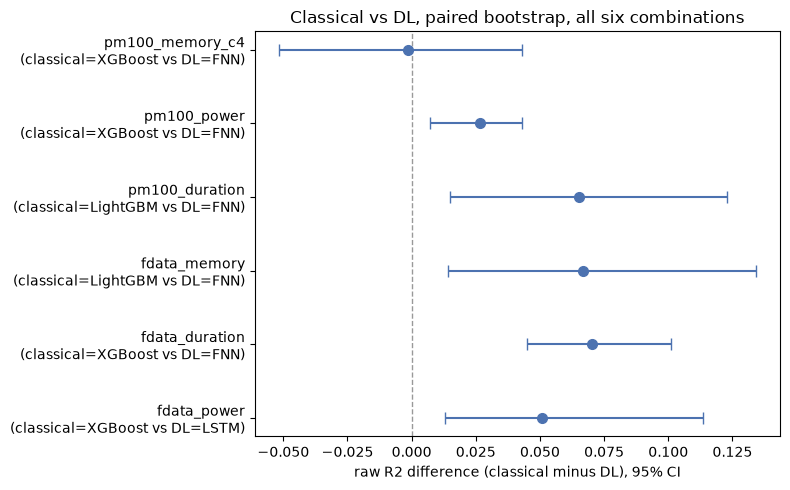

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
combos = list(bootstrap_results.keys())
y_pos = np.arange(len(combos))
means = [bootstrap_results[c]["raw_R2_delta_mean"] for c in combos]
los = [bootstrap_results[c]["raw_R2_ci_lo"] for c in combos]
his = [bootstrap_results[c]["raw_R2_ci_hi"] for c in combos]
err_lo = [m - lo for m, lo in zip(means, los)]
err_hi = [hi - m for hi, m in zip(his, means)]

ax.errorbar(means, y_pos, xerr=[err_lo, err_hi], fmt="o", color="#4C72B0", capsize=4, markersize=7)
ax.axvline(0, color="#999999", linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
labels = [f"{c}\n(classical={bootstrap_results[c]['classical_model']} vs "
          f"DL={bootstrap_results[c]['dl_arch']})" for c in combos]
ax.set_yticklabels(labels)
ax.set_xlabel("raw R2 difference (classical minus DL), 95% CI")
ax.set_title("Classical vs DL, paired bootstrap, all six combinations")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "notebook08b_classical_vs_dl_raw_r2_delta.png", dpi=150, bbox_inches="tight")
plt.show()

## Discussion

**Classical beats DL robustly (every CI excludes zero, on all three metrics) on four of six
combinations: `fdata_power`, `fdata_duration`, `fdata_memory`, `pm100_power`.** Raw R2 deltas
range from +0.0265 (`pm100_power`) to +0.0704 (`fdata_duration`), all with the full 95%
interval on the positive side. Log R2 agrees on all four, though `fdata_duration` (CI
[0.0034, 0.0385]) and `fdata_memory` (CI [0.0010, 0.1241]) both have a lower bound close to
zero -- real, but not by a wide margin. MedAE agrees too, with classical's median error
robustly lower on every one of these four (win share 100% on three of them, 99.95% on
`fdata_memory`).

**`pm100_duration`: classical wins robustly on R2 (both spaces), but not on MedAE.** Raw R2
+0.0653 [0.0149, 0.1227], log R2 +0.1078 [0.0442, 0.2095], both excluding zero. MedAE delta
-132.75, but its CI ([-696.21, 15.73]) includes zero -- not distinguishable from test-sampling
noise at 95%, even though classical still wins the row majority of resamples (95.2%).

**`pm100_memory_c4` is the one combination where this isn't a classical win at all.** Raw R2
delta is slightly NEGATIVE (-0.0014), CI [-0.0518, 0.0428] spanning both signs, and DL wins
50.9% of resamples -- a real tie, not a small classical edge. Log R2 delta is also negative
(-0.0044), CI [-0.0156, 0.0016] including zero, and here DL wins the clear majority of
resamples (90.25% -- classical's own win share is only 9.75%). The one metric where classical
is robust on this combination is MedAE: delta -3.08, CI [-20.30, -0.43], excluding zero (just
barely, the upper bound is -0.43), win share 98.35%. Read plainly: on `pm100_memory_c4`, DL
and classical are statistically indistinguishable on R2 in both spaces (and DL most likely
wins in log space specifically), while classical has a real but modest edge on median error.
This is consistent with `06f_dl_comparison.ipynb`'s own point estimates for this combination
being nearly tied (FNN raw R2 0.9660 vs. XGBoost's adopted 0.9658) -- the bootstrap confirms
that near-tie is real, not resolved by a hidden margin.

**Taken together**: DL's raw-R2-level competitiveness in `06f`'s point-estimate table survives
a real significance check on only one combination (`pm100_memory_c4`, and even there as a tie,
not a DL win) out of six. Everywhere else, the classical-ahead finding already reported in
`06f`/`08` holds up under a proper paired bootstrap, not just as a point-estimate comparison.